In [57]:
import sys
import time
import chipwhisperer as cw
import numpy as np
import matplotlib.pyplot as plt
import struct

FLASH_BASE = 0x08000000
#FLASH_SIZE = 512 * 1024      # STM32L452RE: 512 KB
FLASH_SIZE = 256      # test
CHUNK = 64                   # SAM3U RX buffer holds only 128-200 bytes
BAUD = 115200
#BYTE_GAP = 0.01              # back-to-back bytes get NACKed by the bootloader
BYTE_GAP = 0.0001              # back-to-back bytes get NACKed by the bootloader
RETRIES = 3
out_path = "flash_dump.bin"


def set_debug_pin(value):
    if value:
        scope.io.tio3 = "gpio_high"
    else:
        scope.io.tio3 = "gpio_low"
        
def rx(n, timeout=300):
    """Read up to n bytes; returns fewer on timeout."""
    return ser.read(n, timeout=timeout).encode("latin-1")

def tx(data, write_single_bytes=False):
    if write_single_bytes:
        for b in data:
            ser.write(bytes([b]))
            if BYTE_GAP:
                time.sleep(BYTE_GAP)
    else:
        ser.write(data)

def enter_bootloader():
    """BOOT0 high, reset, then send 0x7F for auto-baud."""
    for _ in range(RETRIES):
        print("enter_bootloader() called")  # temporary debug
        scope.io.pdic = "high"
        time.sleep(0.05)
        scope.io.nrst = "low"
        time.sleep(0.2)
        scope.io.nrst = "high_z"
        time.sleep(0.5)
        ser.flush()
        tx(b"\x7f")
        reply = rx(1)
        if reply == b"\x79":
            return
        print(f"  handshake reply: {reply.hex() or '(none)'}")
    raise RuntimeError("no ACK to 0x7F handshake")


def cmd(code):
    ser.flush()                       # resync: drop leftovers
    tx(bytes([code, code ^ 0xFF]))
    return rx(1)


def read_mem(addr, length):
    """Read Memory command (0x11), length 1..256."""
    set_debug_pin(False)
    # send 0x11 0xEE + wait for ACK
    if cmd(0x11) != b"\x79":
        raise RuntimeError("Read Memory NACK")

    # send address MSB ... LSB
    # send xx xx xx xx xor + wait for ACK
    a = addr.to_bytes(4, "big")
    tx(a + bytes([a[0] ^ a[1] ^ a[2] ^ a[3]]))
    if rx(1) != b"\x79":
        raise RuntimeError(f"address NACK at 0x{addr:08X}")

    # send nuber of bytes to read
    # send xx xor + wait for ACK
    #set_debug_pin(False)
    tx(bytes([length - 1, (length - 1) ^ 0xFF]))
    set_debug_pin(True)
    if rx(1) != b"\x79":
        raise RuntimeError("length NACK")
    
    data = rx(length, timeout=1000)
    if len(data) != length:
        raise RuntimeError(f"short read at 0x{addr:08X}: {len(data)}/{length}")
    return data


def read_chunk_with_retry(addr, length):
    for attempt in range(RETRIES):
        try:
            return read_mem(addr, length)
        except RuntimeError as e:
            print(f"\n  retry {attempt + 1}/{RETRIES}: {e}")
            enter_bootloader()        # clean state, then try again
    raise RuntimeError(f"giving up at 0x{addr:08X}")

def init_logic_analyser_and_adc(scope):
    scope.errors.clear()
    scope.adc.segments = 1
    scope.gain.db = 25

    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"

    scope.adc.offset = 0
    scope.adc.basic_mode = "falling_edge"   
    scope.adc.samples = 4000
    scope.adc.presamples = 0
    scope.adc.lo_gain_errors_disabled = True
    scope.gain.db = 25                      # start modest; raise if trace is flat/noisy, lower if clipping
    
    scope.glitch.trigger_src = "ext_single"   # glitch also fires on that trigger
    
    # --- Logic analyzer: record trigger + glitch signals ---
    scope.LA.enabled = True
    scope.LA.capture_group = 'CW 20-pin'      # glitch or CW 20-pin
    # other groups: 'CW 20-pin' (shows your trigger pin / IO), 'USB'
    scope.LA.capture_depth = 4000
    scope.LA.trigger_source = 'capture'     
    scope.LA.oversampling_factor = 1       # 1 = highest time resolution
    scope.LA.downsample = 1

def get_product_id():
    # Get ID as a sanity check (expect 0462 for the L45x family)
    if cmd(0x02) == b"\x79":
        n = rx(1)[0]
        pid = rx(n + 1)
        rx(1)
        print("product ID:", pid.hex())

def capture_with_la(group, addr, length, glitch=False, trigger='falling_tio1'):
    scope.errors.clear()

    if glitch:
        scope.glitch.enabled = True
        scope.glitch.clk_src = 'pll'
        scope.glitch.trigger_src = 'ext_single'
        scope.io.glitch_hp = True
        scope.io.glitch_lp = False
    else:
        scope.glitch.enabled = False
        scope.io.glitch_hp = False
        scope.io.glitch_lp = False

    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"

    scope.LA.enabled = True
    scope.LA.capture_group = group
    scope.LA.capture_depth = 2000
    scope.LA.downsample = 1   # try 100 to 1000 until you see the whole exchange
    scope.LA.trigger_source = trigger      # direct pin trigger, no ADC involved
    scope.LA.oversampling_factor = 1

    ser.flush()
    scope.errors.clear()
    scope.arm()
    time.sleep(0.01)
    scope.LA.arm()                        
    #data = read_chunk_with_retry(addr, length)
    time.sleep(0.003)
    
    data = 1
    enter_bootloader()
    #data = read_mem(addr, length)
    #get_product_id()

    ret = scope.capture()
    if ret:
        print("ADC capture timeout - trigger not seen")
        return None

    raw = scope.LA.read_capture_data()
    trace = scope.get_last_trace()
    sigs = {}
    for i in range(9):
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break

    #scope.LA.enabled = False
    time.sleep(0.05)
    return sigs, data, trace

def time_axis(scope, sig, unit='us'):
    la_rate = scope.LA.sampling_clock_frequency  # Hz; verify this name against print(scope.LA)
    sample_period = 1.0 / la_rate                # seconds per LA sample
    scale = {'s': 1, 'ms': 1e3, 'us': 1e6, 'ns': 1e9}[unit]
    return np.arange(len(sig)) * sample_period * scale


def capture_power_trace(cmd_bytes, timeout=2):
    """Arm the ADC, send the command bytes, capture, return the raw power trace."""
    scope.arm()
    target.write(cmd_bytes)
    ret = scope.capture(timeout=timeout)
    if ret:
        print("ADC capture timeout - trigger not seen")
        return None
    return scope.get_last_trace()

def auto_unit(duration_s):
    """Pick a sensible time unit based on total duration in seconds."""
    if duration_s >= 1:
        return 's', 1
    elif duration_s >= 1e-3:
        return 'ms', 1e3
    elif duration_s >= 1e-6:
        return 'us', 1e6
    else:
        return 'ns', 1e9
        
def plot_power_trace(trace, title="Power trace", unit=None):
    if trace is None:
        print("No trace to plot")
        return
    adc_rate = scope.clock.adc_freq  # confirm attribute name against print(scope.clock)
    n = len(trace)
    duration_s = n / adc_rate

    if unit is None:
        unit, scale = auto_unit(duration_s)
    else:
        scale = {'s': 1, 'ms': 1e3, 'us': 1e6, 'ns': 1e9}[unit]

    t = (np.arange(n) / adc_rate) * scale

    plt.figure(figsize=(12, 4))
    plt.plot(t, trace, linewidth=0.8)
    plt.xlabel(f"time ({unit})")
    plt.ylabel("ADC value")
    plt.title(title)
    plt.tight_layout()
    plt.show()

def plot_la_trace_cw_20p(scope, sigs):
    labels = {0: "tio1 (TX)", 1: "tio2 (RX)", 2: "tio3"}
    fig, axes = plt.subplots(len(labels), 1, figsize=(12, 3), sharex=True, squeeze=False)
    for ax, (i, name) in zip(axes[:, 0], labels.items()):
        sig = sigs[i]
        t = time_axis(scope,sig, unit)
        ax.step(t, sig, where="post")   # t must be the x argument here
        ax.set_ylabel(name)
        ax.set_yticks([0, 1])
        ax.set_ylim(-0.2, 1.2)
    axes[-1, 0].set_xlabel(f"time ({unit})")
    plt.tight_layout()
    plt.show()


scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen                   
scope.glitch.phase_

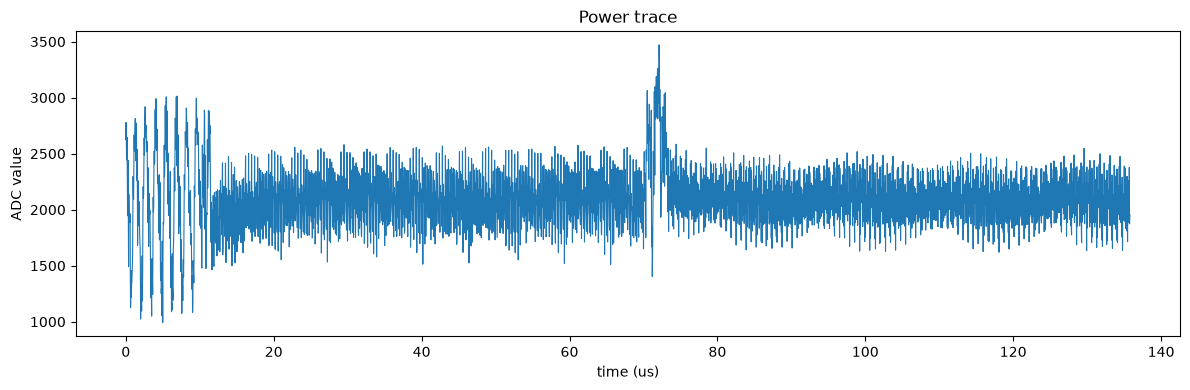

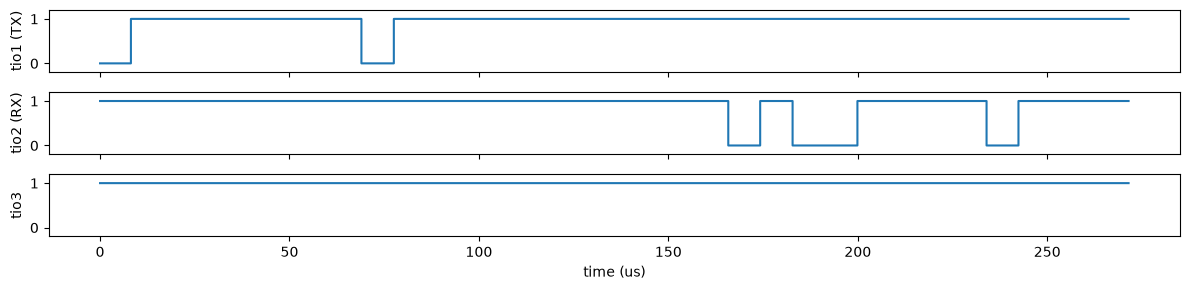

In [58]:
%run ./LoadSaveTraces.ipynb

try:
    scope.dis()
except:
    pass

scope = cw.scope()
scope.default_setup()


size = FLASH_SIZE
# --- get the LA's actual sample rate ---
unit = 'us'
addr = 0x80000
length = 256

target = cw.target(scope, cw.targets.SimpleSerial)
scope.io.tio1 = "serial_tx"
scope.io.tio2 = "serial_rx"
scope.io.tio3 = "gpio_high"
set_debug_pin(True)

ser = target.ser
ser.setBaud(BAUD)
ser.setParity("even")

init_logic_analyser_and_adc(scope)

all_traces = []
meta_data = []

for n in range(1,5):
    sigs1, data1, trace = capture_with_la('CW 20-pin', addr, length, glitch=False)
    all_traces.append(trace)
    meta_data.append({'index':n, 'Name': 'trace', 'color': 'green', 'label': 'RDP0'})
    print(i, scope.adc.errors)
    if scope.adc.errors:
        break

adc_rate = scope.clock.adc_freq   # read once, in Hz, e.g. 29538459.0
unit, scale = calc_unit(all_traces[0], adc_rate)
save_sweep_hdf5('test_traces.h5', all_traces, meta_data, adc_rate, unit)

plot_power_trace(trace)

plot_la_trace_cw_20p(scope, sigs1)



In [55]:
print(scope.errors)
print(scope.adc.errors)


sam_errors      = False
sam_led_setting = Default
XADC errors     = False
ADC errors      = segmenting error, 
extclk error    = False
trace errors    = False

segmenting error, 


In [24]:
import chipwhisperer as cw
try:
    scope.dis()
except:
    pass

scope = cw.scope()
#scope.upgrade_firmware()
print(cw.__version__)
print(scope.fw_version)

(ChipWhisperer Scope ERROR|File naeusbchip.py:113) Scope already disconnected!


7.0.0
{'major': 1, 'minor': 2, 'debug': 0}
